# Лабораторна робота №10 — Бустинг (AdaBoost і Gradient Boosting)

Проєкт DocVerify — побудова класифікаторів на основі бустингу, вплив темпу навчання й кількості ітерацій, дослідження перенавчання та стійкості до шуму порівняно з Random Forest

**Ланцюжок роботи:** підготовка даних → AdaBoost → порівняння з Random Forest → Gradient Boosting → дослідження learning_rate і n_estimators → аналіз перенавчання → додавання шуму → порівняння стійкості моделей → висновок.

**Як запускати.** Потрібні `numpy`, `pandas`, `matplotlib`, `scikit-learn` та `ipykernel`. Виконайте всі комірки (Run All): навчання моделей, дослідження параметрів, таблиці, графіки та висновки обчислюються під час запуску. Результати зберігаються в папці `outputs`.

## 0. Підключення бібліотек і налаштування

Використовуються ті самі бібліотеки та параметри розбиття, що й у попередній лабораторній роботі. Якщо середовище не має потрібних пакетів, встановіть їх у терміналі VS Code:

```bash
python -m pip install numpy pandas matplotlib scikit-learn notebook ipykernel
```


In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42
TEST_SIZE = 0.20

TARGET = "document_type"
AUTH_COLUMN = "authenticity"

FEATURES_CSV = Path("data/features_lab2.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 65)

print("Бібліотеки імпортовано.")
print("scikit-learn:", sklearn.__version__)
print("Робоча директорія:", Path.cwd())
print("Папка результатів:", OUTPUT_DIR.resolve())


Бібліотеки імпортовано.
scikit-learn: 1.8.0
Робоча директорія: d:\Paru\4\DocVerify
Папка результатів: D:\Paru\4\DocVerify\outputs


## 1. Завантаження даних DocVerify

Якщо ноутбук запущено з кореневої папки репозиторію, використовується локальний `data/features_lab2.csv`. Якщо локального файла немає, ноутбук спробує завантажити CSV із відкритого GitHub-репозиторію команди.


In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "MariiaHudymenko/DocVerify/"
    "main/data/features_lab2.csv"
)

if FEATURES_CSV.exists():
    print("Джерело даних: локальний файл", FEATURES_CSV)
    df = pd.read_csv(FEATURES_CSV)
else:
    print("Локальний CSV не знайдено. Спроба завантаження з GitHub...")
    df = pd.read_csv(DATA_URL)

NUMERIC_COLS = [
    "width",
    "height",
    "file_size_bytes",
    "aspect_ratio",
    "std_brightness",
    "dark_pixel_ratio"
]

CATEGORICAL_COLS = [
    "source_dataset",
    "authenticity"
]

REQUIRED_COLS = [
    TARGET,
    *NUMERIC_COLS,
    *CATEGORICAL_COLS
]

missing = sorted(set(REQUIRED_COLS) - set(df.columns))
if missing:
    raise ValueError(f"У CSV не вистачає колонок: {missing}")

print("\nІНФОРМАЦІЯ ПРО ДАТАСЕТ")
print("Кількість документів:", len(df))
print("Кількість класів:", df[TARGET].nunique())
print("Кількість колонок у CSV:", len(df.columns))
print("Пропущених значень authenticity:", df[AUTH_COLUMN].isna().sum())

display(df.head())

if (len(df), df[TARGET].nunique()) != (3682, 20):
    print("Увага: кількість об'єктів або класів відрізняється від набору ЛР №9.")


Джерело даних: локальний файл data\features_lab2.csv

ІНФОРМАЦІЯ ПРО ДАТАСЕТ
Кількість документів: 3682
Кількість класів: 20
Кількість колонок у CSV: 12
Пропущених значень authenticity: 3349


,filename,document_type,source_dataset,authenticity,width,height,file_size_bytes,aspect_ratio,mean_brightness,std_brightness,dark_pixel_ratio,color_saturation_mean
0,rahunok/rahunok_0000.png,рахунок,RVL-CDIP,NaN,802,1000,100163,0.802,250.871021,26.578634,0.015262,0.0
1,rahunok/rahunok_0001.png,рахунок,RVL-CDIP,NaN,777,1000,198897,0.777,234.195624,65.284716,0.080224,0.0
2,rahunok/rahunok_0002.png,рахунок,RVL-CDIP,NaN,754,1000,349049,0.754,231.765775,62.040539,0.083447,0.0
3,rahunok/rahunok_0003.png,рахунок,RVL-CDIP,NaN,776,1000,136111,0.776,246.799001,39.766490,0.031683,0.0
4,rahunok/rahunok_0004.png,рахунок,RVL-CDIP,NaN,775,1000,188636,0.775,244.556391,42.629211,0.039920,0.0


## 2. Підготовка train/test та 13 ознак

Відтворюємо підготовку з ЛР №9:

- `authenticity` — пропущені значення замінюємо на `not_applicable`;
- цільова змінна `document_type` кодується через `LabelEncoder`;
- `train_test_split`: 80/20, `stratify=y`, `random_state=42`;
- IQR-межі для `width` і `file_size_bytes` обчислюються лише на train;
- шість числових ознак масштабуються через `StandardScaler`;
- категоріальні ознаки кодуються через `OneHotEncoder`;
- `mean_brightness` і `color_saturation_mean` не додаються, щоб зберегти простір ознак із ЛР №9.

Таке саме розбиття дає змогу порівнювати результати моделей на однакових даних.


In [3]:
df = df.copy()
df[AUTH_COLUMN] = df[AUTH_COLUMN].fillna("not_applicable")

for column in NUMERIC_COLS:
    df[column] = pd.to_numeric(df[column], errors="raise")

if df[NUMERIC_COLS + [TARGET, "source_dataset", AUTH_COLUMN]].isna().any().any():
    raise ValueError("У потрібних ознаках залишилися неочікувані пропуски.")

le_target = LabelEncoder()
y = le_target.fit_transform(df[TARGET])

train_idx, test_idx = train_test_split(
    df.index,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

df_train = df.loc[train_idx].copy()
df_test = df.loc[test_idx].copy()

y_train = y[train_idx]
y_test = y[test_idx]

def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr)

CAP_COLS = ["width", "file_size_bytes"]
cap_bounds = {
    column: iqr_bounds(df_train[column])
    for column in CAP_COLS
}

for column, (lower, upper) in cap_bounds.items():
    df_train[column] = df_train[column].clip(lower=lower, upper=upper)
    df_test[column] = df_test[column].clip(lower=lower, upper=upper)

# Сумісність із різними версіями scikit-learn
try:
    ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
except TypeError:
    ohe = OneHotEncoder(sparse=False, handle_unknown="ignore")

X_train_cat = ohe.fit_transform(df_train[CATEGORICAL_COLS])
X_test_cat = ohe.transform(df_test[CATEGORICAL_COLS])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(df_train[NUMERIC_COLS])
X_test_num = scaler.transform(df_test[NUMERIC_COLS])

X_train = np.hstack([X_train_num, X_train_cat])
X_test = np.hstack([X_test_num, X_test_cat])

feature_names = NUMERIC_COLS + list(
    ohe.get_feature_names_out(CATEGORICAL_COLS)
)

print("ПІДГОТОВКА ДАНИХ ЗАВЕРШЕНА")
print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Кількість ознак:", len(feature_names))
print("Кількість класів:", len(le_target.classes_))
print("IQR-межі:", cap_bounds)

assert X_train.shape[1] == X_test.shape[1] == len(feature_names)
assert set(train_idx).isdisjoint(set(test_idx))
assert not np.isnan(X_train).any()
assert not np.isnan(X_test).any()

if len(df) == 3682 and df[TARGET].nunique() == 20:
    assert X_train.shape == (2945, 13)
    assert X_test.shape == (737, 13)
    print("\nПеревірка пройдена: 2945 train, 737 test, 13 ознак.")



ПІДГОТОВКА ДАНИХ ЗАВЕРШЕНА
Train: (2945, 13)
Test: (737, 13)
Кількість ознак: 13
Кількість класів: 20
IQR-межі: {'width': (719.5, 811.5), 'file_size_bytes': (-253772.5, 782807.5)}

Перевірка пройдена: 2945 train, 737 test, 13 ознак.


## 3. Допоміжна функція оцінювання моделей

Для кожного класифікатора фіксуємо:
- точність на навчальній вибірці (`train_accuracy`);
- точність на тестовій вибірці (`test_accuracy`);
- F1-score macro на тестовій вибірці;
- розрив між train і test (`gap`);
- час навчання.

Тестова вибірка залишається незмінною в усіх експериментах.


In [4]:
def evaluate_model(model, X_train, y_train_fit, X_test, y_test):
    start = time.perf_counter()
    model.fit(X_train, y_train_fit)
    fit_seconds = time.perf_counter() - start

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_accuracy = accuracy_score(y_train_fit, pred_train)
    test_accuracy = accuracy_score(y_test, pred_test)

    return {
        "model": model,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "gap": train_accuracy - test_accuracy,
        "f1_macro": f1_score(
            y_test, pred_test, average="macro", zero_division=0
        ),
        "fit_seconds": fit_seconds,
        "pred_test": pred_test
    }


## 4. Частина 1 — AdaBoostClassifier

AdaBoost послідовно навчає слабкі класифікатори. Після кожного кроку більшу вагу отримують об'єкти, які попередні класифікатори визначили неправильно.

Спочатку будуємо `AdaBoostClassifier` із параметрами за замовчуванням і `random_state=42`, як у методичних рекомендаціях.


In [5]:
ada = AdaBoostClassifier(random_state=RANDOM_STATE)
ada_result = evaluate_model(ada, X_train, y_train, X_test, y_test)

print("ADABOOST — РЕЗУЛЬТАТИ")
print(f"Train accuracy: {ada_result['train_accuracy']:.4f}")
print(f"Test accuracy:  {ada_result['test_accuracy']:.4f}")
print(f"F1-macro:       {ada_result['f1_macro']:.4f}")
print(f"Train-Test gap: {ada_result['gap']:.4f}")
print(f"Час навчання:   {ada_result['fit_seconds']:.3f} с")

print("\nClassification Report:")
print(classification_report(
    y_test,
    ada_result["pred_test"],
    labels=np.arange(len(le_target.classes_)),
    target_names=le_target.classes_,
    zero_division=0
))


ADABOOST — РЕЗУЛЬТАТИ
Train accuracy: 0.3419
Test accuracy:  0.3446
F1-macro:       0.3188
Train-Test gap: -0.0027
Час навчання:   0.174 с

Classification Report:
                    precision    recall  f1-score   support

         ID-картка       1.00      1.00      1.00        20
             email       0.36      0.71      0.48        38
            анкета       0.00      0.00      0.00        38
            бюджет       0.00      0.00      0.00        38
         квитанція       1.00      1.00      1.00        40
              лист       0.00      0.00      0.00        44
наукова публікація       0.15      0.13      0.14        38
     науковий звіт       0.00      0.00      0.00        38
    новинна стаття       0.00      0.00      0.00        38
           паспорт       1.00      1.00      1.00        27
 посвідчення водія       1.00      1.00      1.00        36
       презентація       0.00      0.00      0.00        38
           рахунок       0.00      0.00      0.00       

## 5. Порівняння AdaBoost із Random Forest із ЛР №9

Для контрольного порівняння повторно навчаємо Random Forest із параметрами базової моделі з лабораторної №9: 200 дерев, bootstrap-вибірки, `max_features='sqrt'`, `random_state=42`.

Це дає змогу порівняти алгоритми на тих самих train/test і після тієї самої підготовки ознак.


In [6]:
rf200 = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_result = evaluate_model(rf200, X_train, y_train, X_test, y_test)

print("RANDOM FOREST — 200 ДЕРЕВ")
print(f"Train accuracy: {rf_result['train_accuracy']:.4f}")
print(f"OOB accuracy:   {rf200.oob_score_:.4f}")
print(f"Test accuracy:  {rf_result['test_accuracy']:.4f}")
print(f"F1-macro:       {rf_result['f1_macro']:.4f}")
print(f"Train-Test gap: {rf_result['gap']:.4f}")
print(f"Час навчання:   {rf_result['fit_seconds']:.3f} с")

part1_comparison = pd.DataFrame([
    {
        "model": "AdaBoost",
        "train_accuracy": ada_result["train_accuracy"],
        "test_accuracy": ada_result["test_accuracy"],
        "f1_macro": ada_result["f1_macro"],
        "gap": ada_result["gap"],
        "fit_seconds": ada_result["fit_seconds"]
    },
    {
        "model": "Random Forest (200)",
        "train_accuracy": rf_result["train_accuracy"],
        "test_accuracy": rf_result["test_accuracy"],
        "f1_macro": rf_result["f1_macro"],
        "gap": rf_result["gap"],
        "fit_seconds": rf_result["fit_seconds"]
    }
])

display(part1_comparison.round(4))
part1_comparison.to_csv(
    OUTPUT_DIR / "lab10_adaboost_random_forest.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Збережено: outputs/lab10_adaboost_random_forest.csv")


RANDOM FOREST — 200 ДЕРЕВ
Train accuracy: 1.0000
OOB accuracy:   0.3671
Test accuracy:  0.3786
F1-macro:       0.4000
Train-Test gap: 0.6214
Час навчання:   0.654 с


,model,train_accuracy,test_accuracy,f1_macro,gap,fit_seconds
0,AdaBoost,0.3419,0.3446,0.3188,-0.0027,0.1744
1,Random Forest (200),1.0000,0.3786,0.4000,0.6214,0.6539


Збережено: outputs/lab10_adaboost_random_forest.csv


## 6. Частина 2 — Gradient Boosting: вплив learning_rate

Перевіряємо значення `learning_rate = 0.01, 0.1, 0.5, 1.0` за фіксованого `n_estimators=200`. Для кожного варіанта обчислюємо train/test accuracy, F1-macro, розрив train-test і час навчання.

У межах цієї лабораторної найкраще значення визначаємо за тестовою точністю, як передбачено завданням. У реальних задачах для налаштування гіперпараметрів бажано використовувати окрему validation-вибірку або крос-валідацію, а test залишати для фінальної оцінки.


Навчання Gradient Boosting: learning_rate=0.01
Навчання Gradient Boosting: learning_rate=0.1
Навчання Gradient Boosting: learning_rate=0.5
Навчання Gradient Boosting: learning_rate=1.0


,learning_rate,n_estimators,train_accuracy,test_accuracy,f1_macro,gap,fit_seconds
0,0.01,200,0.5131,0.3894,0.3889,0.1237,19.4798
1,0.10,200,0.9416,0.3745,0.3966,0.5671,22.3586
2,0.50,200,0.9457,0.3636,0.3827,0.5820,17.7625
3,1.00,200,0.0750,0.0692,0.0455,0.0058,17.6950


Найкращий learning_rate за test accuracy: 0.01
Test accuracy: 0.3894
Збережено: outputs/lab10_gradient_boosting_learning_rates.csv


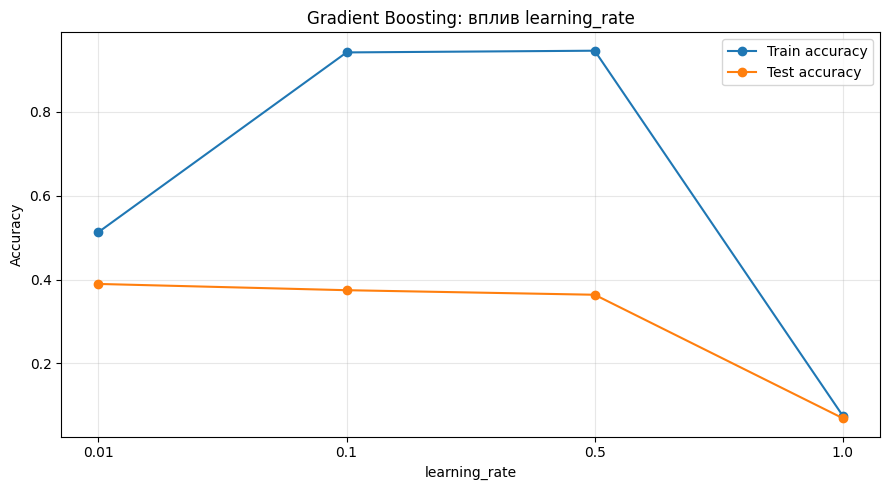

Збережено: outputs/fig_lab10_learning_rate_comparison.png


In [7]:
LEARNING_RATES = [0.01, 0.1, 0.5, 1.0]
GB_N_ESTIMATORS = 200

gb_results = []
gb_models = {}

for lr in LEARNING_RATES:
    print(f"Навчання Gradient Boosting: learning_rate={lr}")

    gb = GradientBoostingClassifier(
        learning_rate=lr,
        n_estimators=GB_N_ESTIMATORS,
        random_state=RANDOM_STATE
    )

    result = evaluate_model(gb, X_train, y_train, X_test, y_test)
    gb_models[lr] = gb

    gb_results.append({
        "learning_rate": lr,
        "n_estimators": GB_N_ESTIMATORS,
        "train_accuracy": result["train_accuracy"],
        "test_accuracy": result["test_accuracy"],
        "f1_macro": result["f1_macro"],
        "gap": result["gap"],
        "fit_seconds": result["fit_seconds"]
    })

gb_lr_df = pd.DataFrame(gb_results).sort_values("learning_rate")
display(gb_lr_df.round(4))

gb_lr_df.to_csv(
    OUTPUT_DIR / "lab10_gradient_boosting_learning_rates.csv",
    index=False,
    encoding="utf-8-sig"
)

best_row = gb_lr_df.sort_values(
    ["test_accuracy", "learning_rate"],
    ascending=[False, True]
).iloc[0]

best_learning_rate = float(best_row["learning_rate"])

print(f"Найкращий learning_rate за test accuracy: {best_learning_rate}")
print(f"Test accuracy: {best_row['test_accuracy']:.4f}")
print("Збережено: outputs/lab10_gradient_boosting_learning_rates.csv")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    gb_lr_df["learning_rate"].astype(str),
    gb_lr_df["train_accuracy"],
    marker="o",
    label="Train accuracy"
)
ax.plot(
    gb_lr_df["learning_rate"].astype(str),
    gb_lr_df["test_accuracy"],
    marker="o",
    label="Test accuracy"
)
ax.set_xlabel("learning_rate")
ax.set_ylabel("Accuracy")
ax.set_title("Gradient Boosting: вплив learning_rate")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "fig_lab10_learning_rate_comparison.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)
print("Збережено: outputs/fig_lab10_learning_rate_comparison.png")


## 7. Gradient Boosting: вплив кількості ітерацій n_estimators

Для найкращого `learning_rate` будуємо модель із 200 ітераціями та використовуємо `staged_predict`. Цей метод повертає прогноз після кожного доданого дерева, тому можна простежити зміну train і test accuracy зі збільшенням кількості ітерацій без повторного навчання моделі для кожного значення.

Найкраща ітерація — та, на якій тестова точність найбільша. Якщо після неї test accuracy зменшується, це є ознакою погіршення узагальнення; сам по собі один спад ще не доводить стійке перенавчання.


Найкраща кількість ітерацій: 62
Найкраща test accuracy: 0.4030
Перше зниження test accuracy після максимуму: 63


,n_estimators,train_accuracy,test_accuracy
9,10,0.3844,0.3650
24,25,0.4003,0.3731
49,50,0.4200,0.3921
99,100,0.4581,0.3976
149,150,0.4849,0.3853
199,200,0.5131,0.3894


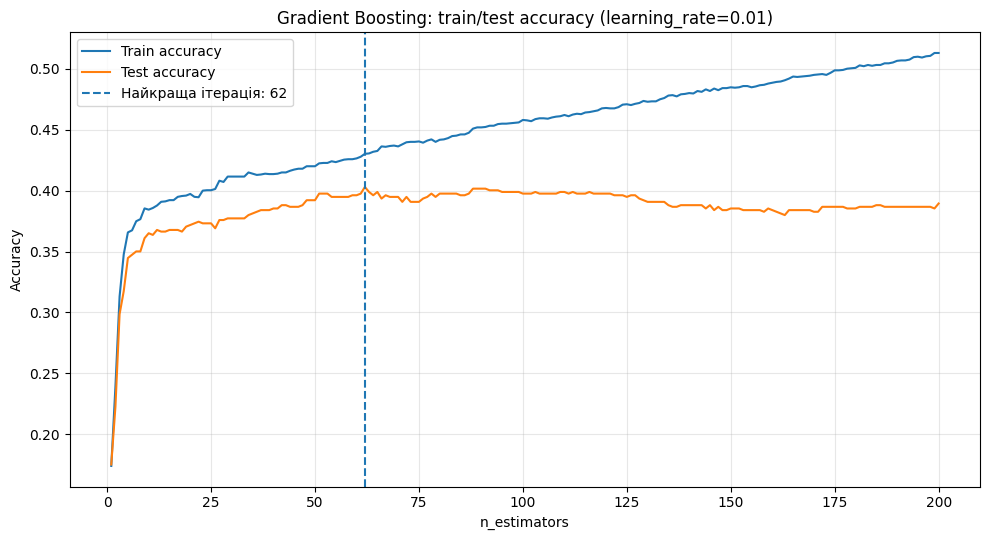

Збережено: outputs/lab10_gradient_boosting_iterations.csv
Збережено: outputs/fig_lab10_estimators_accuracy.png


In [8]:
gb_curve_model = GradientBoostingClassifier(
    learning_rate=best_learning_rate,
    n_estimators=GB_N_ESTIMATORS,
    random_state=RANDOM_STATE
)

start = time.perf_counter()
gb_curve_model.fit(X_train, y_train)
gb_curve_fit_seconds = time.perf_counter() - start

train_curve = []
test_curve = []

for train_pred, test_pred in zip(
    gb_curve_model.staged_predict(X_train),
    gb_curve_model.staged_predict(X_test)
):
    train_curve.append(accuracy_score(y_train, train_pred))
    test_curve.append(accuracy_score(y_test, test_pred))

gb_curve_df = pd.DataFrame({
    "n_estimators": np.arange(1, GB_N_ESTIMATORS + 1),
    "train_accuracy": train_curve,
    "test_accuracy": test_curve
})

best_iteration_row = gb_curve_df.loc[
    gb_curve_df["test_accuracy"].idxmax()
]
best_iteration = int(best_iteration_row["n_estimators"])
best_iteration_test_accuracy = float(best_iteration_row["test_accuracy"])

later_iterations = gb_curve_df[
    gb_curve_df["n_estimators"] > best_iteration
]
first_lower = later_iterations[
    later_iterations["test_accuracy"] < best_iteration_test_accuracy
]

print("Найкраща кількість ітерацій:", best_iteration)
print(f"Найкраща test accuracy: {best_iteration_test_accuracy:.4f}")

if len(first_lower) > 0:
    first_drop_iteration = int(first_lower.iloc[0]["n_estimators"])
    print(
        "Перше зниження test accuracy після максимуму:",
        first_drop_iteration
    )
else:
    first_drop_iteration = None
    print(
        "Після максимуму до 200 ітерацій test accuracy не знизилася."
    )

display(
    gb_curve_df[
        gb_curve_df["n_estimators"].isin([10, 25, 50, 100, 150, 200])
    ].round(4)
)

gb_curve_df.to_csv(
    OUTPUT_DIR / "lab10_gradient_boosting_iterations.csv",
    index=False,
    encoding="utf-8-sig"
)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    gb_curve_df["n_estimators"],
    gb_curve_df["train_accuracy"],
    label="Train accuracy"
)
ax.plot(
    gb_curve_df["n_estimators"],
    gb_curve_df["test_accuracy"],
    label="Test accuracy"
)
ax.axvline(
    best_iteration,
    linestyle="--",
    label=f"Найкраща ітерація: {best_iteration}"
)
ax.set_xlabel("n_estimators")
ax.set_ylabel("Accuracy")
ax.set_title(
    f"Gradient Boosting: train/test accuracy "
    f"(learning_rate={best_learning_rate})"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "fig_lab10_estimators_accuracy.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Збережено: outputs/lab10_gradient_boosting_iterations.csv")
print("Збережено: outputs/fig_lab10_estimators_accuracy.png")


## 8. Частина 3 — дослідження чутливості до шуму

За умовою додаємо шум до 8% міток навчальної вибірки. Тестова вибірка залишається чистою і незмінною.

Оскільки у DocVerify 20 класів, кожну вибрану мітку замінюємо на випадковий клас, відмінний від початкового. Це дає саме помилкову мітку, а не залишає частину об'єктів без змін.

Порівнюємо три алгоритми:
- AdaBoost;
- Gradient Boosting із найкращим знайденим `learning_rate` та 200 ітераціями;
- Random Forest із 200 деревами.

Для кожного алгоритму порівнюємо точність на чистому test до та після навчання на зашумленому train.


In [9]:
NOISE_FRACTION = 0.08
rng = np.random.RandomState(RANDOM_STATE)

y_noisy = y_train.copy()
n_noisy = int(NOISE_FRACTION * len(y_noisy))

noise_indices = rng.choice(
    len(y_noisy),
    size=n_noisy,
    replace=False
)

all_classes = np.arange(len(le_target.classes_))

for position in noise_indices:
    original_label = y_noisy[position]
    alternative_labels = all_classes[all_classes != original_label]
    y_noisy[position] = rng.choice(alternative_labels)

changed_labels = int(np.sum(y_noisy != y_train))

print("ДОДАВАННЯ ШУМУ")
print("Розмір train:", len(y_train))
print("Заплановано змінити міток:", n_noisy)
print("Фактично змінено міток:", changed_labels)
print(f"Частка змінених міток: {changed_labels / len(y_train):.2%}")
print("Кількість класів:", len(all_classes))

assert changed_labels == n_noisy
assert np.array_equal(y_test, y_test.copy())


ДОДАВАННЯ ШУМУ
Розмір train: 2945
Заплановано змінити міток: 235
Фактично змінено міток: 235
Частка змінених міток: 7.98%
Кількість класів: 20


## 9. Навчання моделей на зашумлених даних

Для чесного порівняння використовуємо ті самі архітектури й параметри, що й у базових експериментах. В оцінці на test використовуються початкові, незмінені `y_test`.


In [10]:
noisy_models = {
    "AdaBoost": AdaBoostClassifier(
        random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        learning_rate=best_learning_rate,
        n_estimators=GB_N_ESTIMATORS,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        bootstrap=True,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

clean_test_scores = {
    "AdaBoost": ada_result["test_accuracy"],
    "Gradient Boosting": float(best_row["test_accuracy"]),
    "Random Forest": rf_result["test_accuracy"]
}

noisy_rows = []
noisy_model_results = {}

for model_name, model in noisy_models.items():
    print("Навчання на зашумлених мітках:", model_name)

    result = evaluate_model(
        model,
        X_train,
        y_noisy,
        X_test,
        y_test
    )
    noisy_model_results[model_name] = result

    baseline_accuracy = clean_test_scores[model_name]
    accuracy_drop = baseline_accuracy - result["test_accuracy"]

    noisy_rows.append({
        "model": model_name,
        "train_accuracy_on_noisy_labels": result["train_accuracy"],
        "clean_test_accuracy_before_noise": baseline_accuracy,
        "clean_test_accuracy_after_noise": result["test_accuracy"],
        "f1_macro_after_noise": result["f1_macro"],
        "accuracy_drop": accuracy_drop,
        "fit_seconds": result["fit_seconds"]
    })

noise_comparison_df = pd.DataFrame(noisy_rows)
display(noise_comparison_df.round(4))

noise_comparison_df.to_csv(
    OUTPUT_DIR / "lab10_noise_sensitivity.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Збережено: outputs/lab10_noise_sensitivity.csv")


Навчання на зашумлених мітках: AdaBoost
Навчання на зашумлених мітках: Gradient Boosting
Навчання на зашумлених мітках: Random Forest


,model,train_accuracy_on_noisy_labels,clean_test_accuracy_before_noise,clean_test_accuracy_after_noise,f1_macro_after_noise,accuracy_drop,fit_seconds
0,AdaBoost,0.3158,0.3446,0.3433,0.3118,0.0014,0.3080
1,Gradient Boosting,0.4896,0.3894,0.3772,0.3801,0.0122,19.6347
2,Random Forest,1.0000,0.3786,0.3609,0.3778,0.0176,0.5424


Збережено: outputs/lab10_noise_sensitivity.csv


## 10. Графік чутливості моделей до шуму

На графіку порівнюємо тестову точність до та після додавання шуму до навчальних міток. Чим менше зменшення test accuracy, тим стійкішою виявилася модель у цьому експерименті.


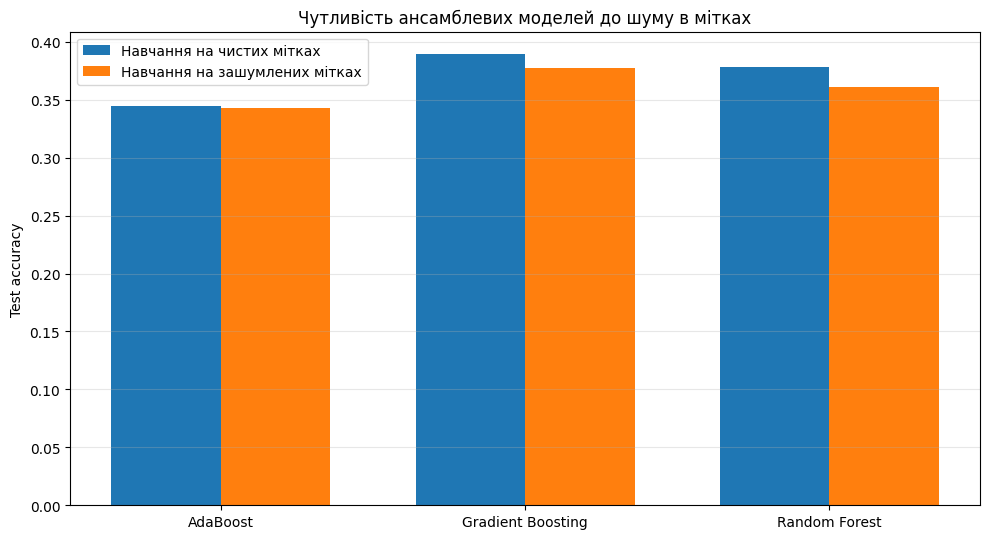

Збережено: outputs/fig_lab10_noise_sensitivity.png


In [11]:
plot_noise_df = noise_comparison_df.set_index("model")

x = np.arange(len(plot_noise_df))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(
    x - width / 2,
    plot_noise_df["clean_test_accuracy_before_noise"],
    width,
    label="Навчання на чистих мітках"
)
ax.bar(
    x + width / 2,
    plot_noise_df["clean_test_accuracy_after_noise"],
    width,
    label="Навчання на зашумлених мітках"
)

ax.set_xticks(x, plot_noise_df.index)
ax.set_ylabel("Test accuracy")
ax.set_title("Чутливість ансамблевих моделей до шуму в мітках")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "fig_lab10_noise_sensitivity.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Збережено: outputs/fig_lab10_noise_sensitivity.png")


## 11. Підсумкова таблиця ансамблевих методів

Порівнюємо базові моделі, навчені на чистих даних. Для Gradient Boosting беремо найкращий варіант серед перевірених `learning_rate` за тестовою точністю при 200 ітераціях.


In [12]:
gb_best_result = gb_models[best_learning_rate]

gb_best_train_pred = gb_best_result.predict(X_train)
gb_best_test_pred = gb_best_result.predict(X_test)

gb_best_train_accuracy = accuracy_score(y_train, gb_best_train_pred)
gb_best_test_accuracy = accuracy_score(y_test, gb_best_test_pred)
gb_best_f1 = f1_score(
    y_test,
    gb_best_test_pred,
    average="macro",
    zero_division=0
)

ensemble_comparison_df = pd.DataFrame([
    {
        "model": "AdaBoost",
        "train_accuracy": ada_result["train_accuracy"],
        "test_accuracy": ada_result["test_accuracy"],
        "f1_macro": ada_result["f1_macro"],
        "train_test_gap": ada_result["gap"],
        "fit_seconds": ada_result["fit_seconds"]
    },
    {
        "model": f"Gradient Boosting (lr={best_learning_rate}, 200)",
        "train_accuracy": gb_best_train_accuracy,
        "test_accuracy": gb_best_test_accuracy,
        "f1_macro": gb_best_f1,
        "train_test_gap": gb_best_train_accuracy - gb_best_test_accuracy,
        "fit_seconds": float(best_row["fit_seconds"])
    },
    {
        "model": "Random Forest (200)",
        "train_accuracy": rf_result["train_accuracy"],
        "test_accuracy": rf_result["test_accuracy"],
        "f1_macro": rf_result["f1_macro"],
        "train_test_gap": rf_result["gap"],
        "fit_seconds": rf_result["fit_seconds"]
    }
])

display(ensemble_comparison_df.round(4))

ensemble_comparison_df.to_csv(
    OUTPUT_DIR / "lab10_ensemble_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Збережено: outputs/lab10_ensemble_comparison.csv")


,model,train_accuracy,test_accuracy,f1_macro,train_test_gap,fit_seconds
0,AdaBoost,0.3419,0.3446,0.3188,-0.0027,0.1744
1,"Gradient Boosting (lr=0.01, 200)",0.5131,0.3894,0.3889,0.1237,19.4798
2,Random Forest (200),1.0000,0.3786,0.4000,0.6214,0.6539


Збережено: outputs/lab10_ensemble_comparison.csv


## 12. Автоматичний підсумок експерименту

Ця комірка формує текстовий файл із фактичними метриками поточного запуску. Саме ці числа потрібно переносити у звіт — не використовуйте попередньо наведені або приблизні значення.


In [13]:
best_noise_model = noise_comparison_df.sort_values(
    "accuracy_drop",
    ascending=True
).iloc[0]

worst_noise_model = noise_comparison_df.sort_values(
    "accuracy_drop",
    ascending=False
).iloc[0]

summary_lines = [
    "ЛАБОРАТОРНА РОБОТА №10 — DocVerify",
    f"Датасет: {len(df)} документів, {df[TARGET].nunique()} класів.",
    f"Train: {len(y_train)}; test: {len(y_test)}; ознак: {len(feature_names)}.",
    f"Поділ: test_size={TEST_SIZE}; stratify=y; random_state={RANDOM_STATE}.",
    "",
    "БАЗОВІ МОДЕЛІ:",
    f"AdaBoost: train={ada_result['train_accuracy']:.4f}; "
    f"test={ada_result['test_accuracy']:.4f}; "
    f"F1-macro={ada_result['f1_macro']:.4f}; gap={ada_result['gap']:.4f}.",
    f"Gradient Boosting: learning_rate={best_learning_rate}; "
    f"n_estimators={GB_N_ESTIMATORS}; "
    f"train={gb_best_train_accuracy:.4f}; "
    f"test={gb_best_test_accuracy:.4f}; F1-macro={gb_best_f1:.4f}.",
    f"Random Forest (200): train={rf_result['train_accuracy']:.4f}; "
    f"test={rf_result['test_accuracy']:.4f}; "
    f"F1-macro={rf_result['f1_macro']:.4f}; gap={rf_result['gap']:.4f}.",
    "",
    "GRADIENT BOOSTING:",
    f"Перевірені learning_rate: {LEARNING_RATES}.",
    f"Найкращий learning_rate за test accuracy: {best_learning_rate}.",
    f"Найкраща кількість ітерацій за staged_predict: {best_iteration}.",
    f"Максимальна test accuracy на кривій: {best_iteration_test_accuracy:.4f}.",
    (
        f"Перше зниження після максимуму: ітерація {first_drop_iteration}."
        if first_drop_iteration is not None
        else "Після максимуму test accuracy до 200 ітерацій не знизилася."
    ),
    "",
    "ШУМ:",
    f"Змінено міток: {changed_labels} із {len(y_train)} "
    f"({changed_labels / len(y_train):.2%}).",
    f"Найменше падіння test accuracy: {best_noise_model['model']} "
    f"({best_noise_model['accuracy_drop']:+.4f}).",
    f"Найбільше падіння test accuracy: {worst_noise_model['model']} "
    f"({worst_noise_model['accuracy_drop']:+.4f}).",
    "",
    "Усі висновки щодо якості та стійкості потрібно формулювати за таблицями "
    "і графіками фактичного запуску."
]

summary_text = "\n".join(summary_lines)
print(summary_text)

(OUTPUT_DIR / "lab10_summary.txt").write_text(
    summary_text,
    encoding="utf-8"
)

print("\nЗбережено: outputs/lab10_summary.txt")


ЛАБОРАТОРНА РОБОТА №10 — DocVerify
Датасет: 3682 документів, 20 класів.
Train: 2945; test: 737; ознак: 13.
Поділ: test_size=0.2; stratify=y; random_state=42.

БАЗОВІ МОДЕЛІ:
AdaBoost: train=0.3419; test=0.3446; F1-macro=0.3188; gap=-0.0027.
Gradient Boosting: learning_rate=0.01; n_estimators=200; train=0.5131; test=0.3894; F1-macro=0.3889.
Random Forest (200): train=1.0000; test=0.3786; F1-macro=0.4000; gap=0.6214.

GRADIENT BOOSTING:
Перевірені learning_rate: [0.01, 0.1, 0.5, 1.0].
Найкращий learning_rate за test accuracy: 0.01.
Найкраща кількість ітерацій за staged_predict: 62.
Максимальна test accuracy на кривій: 0.4030.
Перше зниження після максимуму: ітерація 63.

ШУМ:
Змінено міток: 235 із 2945 (7.98%).
Найменше падіння test accuracy: AdaBoost (+0.0014).
Найбільше падіння test accuracy: Random Forest (+0.0176).

Усі висновки щодо якості та стійкості потрібно формулювати за таблицями і графіками фактичного запуску.

Збережено: outputs/lab10_summary.txt


## 13. Відповіді на контрольні питання

**1. Опишіть схему AdaBoost.**  
AdaBoost послідовно навчає слабкі класифікатори. Після кожного кроку збільшує вагу об'єктів, класифікованих неправильно, а підсумкове рішення отримує зваженим голосуванням.

**2. Як обчислюється вага слабкого класифікатора?**  
Для багатокласового варіанта SAMME вага залежить від помилки слабкого класифікатора:  
`alpha = learning_rate * (ln((1 - error) / error) + ln(K - 1))`,  
де `error` — частка помилок, `K` — кількість класів. Чим менша помилка, тим більша вага класифікатора.

**3. У чому ідея градієнтного бустингу?**  
Моделі навчаються послідовно. Кожна наступна модель наближає прогноз до мінімуму функції втрат, орієнтуючись на антиградієнт втрат попередньої моделі.

**4. Який learning_rate виявився оптимальним?**  
Відповідь береться з таблиці `lab10_gradient_boosting_learning_rates.csv` і виводу комірки 6. У звіті потрібно вказати фактичне значення з вашого запуску.

**5. При якій кількості ітерацій виникло перенавчання?**  
Орієнтир — максимум тестової точності на графіку `fig_lab10_estimators_accuracy.png` і перше її зниження після максимуму. Потрібно враховувати, що одиничне зниження може бути коливанням метрики.

**6. Який метод найстійкіший до шуму й чому?**  
За результатами цього експерименту — модель із найменшим падінням test accuracy у `lab10_noise_sensitivity.csv`. Причину слід пояснити з урахуванням механізму роботи алгоритму та отриманих чисел.

**7. Порівняйте бустинг і бегінг за чутливістю до шуму.**  
Бустинг навчає моделі послідовно й приділяє більше уваги складним або неправильно класифікованим об'єктам, тому помилкові мітки можуть сильніше впливати на наступні кроки. Бегінг навчає моделі незалежно на bootstrap-вибірках і об'єднує їхні прогнози, що часто робить його менш чутливим до окремих шумних об'єктів.


## 14. Файли для звіту

Після виконання всіх комірок у `outputs/` мають бути створені:

| Файл | Призначення |
|---|---|
| `lab10_adaboost_random_forest.csv` | Порівняння AdaBoost і Random Forest |
| `lab10_gradient_boosting_learning_rates.csv` | Порівняння темпів навчання |
| `lab10_gradient_boosting_iterations.csv` | Точність на кожній ітерації |
| `lab10_noise_sensitivity.csv` | Порівняння моделей на зашумлених даних |
| `lab10_ensemble_comparison.csv` | Підсумкова таблиця трьох ансамблевих методів |
| `lab10_summary.txt` | Фактичні результати експерименту |
| `fig_lab10_learning_rate_comparison.png` | Графік впливу learning_rate |
| `fig_lab10_estimators_accuracy.png` | Графік train/test accuracy за ітераціями |
| `fig_lab10_noise_sensitivity.png` | Графік чутливості до шуму |

**Для звіту:** додайте титульний аркуш, короткий опис даних і підготовки, результати трьох частин, таблиці та графіки з `outputs/`, відповіді на контрольні питання й висновок. Усі числові висновки формулюйте після запуску ноутбука за фактичними результатами.
